# Part I – Introduction to Neural Networks

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.linear_model import Perceptron
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras

In [2]:
# Extra: fix the random seeds so re-running gives (almost) the same numbers.
# Neural networks start with random weights, so without this every run differs a little.
keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)

TensorFlow version: 2.21.0
Keras version: 3.15.1


# Task 1.1 – Interpretation

**1. Numerical computation**
**Answer:** `numpy` (as `np`). It does fast maths on arrays (grids) of numbers. All our data (flower measurements, image pixels, house data) is stored as NumPy arrays.

**2. Visualization**
**Answer:** `matplotlib.pyplot` (as `plt`). It draws the charts: the activation-function plot, the clothing image and the accuracy/loss curves.

**3. Classical machine learning**
**Answer:** `scikit-learn` (`sklearn`). Here we use `load_iris` (loads the flower data), `Perceptron` (the simple one-neuron model) and `train_test_split` (splits data into training and test parts).

**4. Neural-network development**
**Answer:** `tensorflow` (as `tf`) and `keras`. TensorFlow is the engine that does the heavy maths of training. Keras sits on top of it and gives simple building blocks (layers, models, `compile`, `fit`) so we can build networks in a few lines.

# Part II – The Perceptron

In [3]:
iris = load_iris()

X = iris.data
y = iris.target

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("Feature names:", iris.feature_names)
print("Target names:", iris.target_names)

Shape of X: (150, 4)
Shape of y: (150,)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: ['setosa' 'versicolor' 'virginica']


In [4]:
X_binary = X[y < 2]
y_binary = y[y < 2]

print("Shape:", X_binary.shape)
print("Classes:", np.unique(y_binary))

Shape: (100, 4)
Classes: [0 1]


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X_binary,
    y_binary,
    test_size=0.2,
    random_state=42,
    stratify=y_binary
)

In [6]:
perceptron = Perceptron(
    random_state=42
)

perceptron.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",1.0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


In [7]:
accuracy = perceptron.score(X_test, y_test)

print("Test accuracy:", accuracy)

Test accuracy: 1.0


In [8]:
# Extra check: the weights (one per feature) and the bias the Perceptron learned
for name, w in zip(iris.feature_names, perceptron.coef_[0]):
    print(f"{name:20s} weight = {w:6.2f}")
print(f"{'bias':20s}        = {perceptron.intercept_[0]:6.2f}")

sepal length (cm)    weight =  -2.10
sepal width (cm)     weight =  -7.60
petal length (cm)    weight =  10.20
petal width (cm)     weight =   4.90
bias                        =  -1.00


# Task 2.1 – Interpretation

**1. What is the Perceptron trying to learn?**
**Answer:** A dividing line that separates the two flower types: setosa (class 0) and versicolor (class 1). It works out a score with z = w₁x₁ + w₂x₂ + w₃x₃ + w₄x₄ + b. If the score is above 0 it says versicolor, otherwise setosa. Because there are 4 features, the “line” is really a flat surface in 4 dimensions (called a *hyperplane*), but the idea is the same.

**2. What do the learned weights represent conceptually?**
**Answer:** How much each feature matters, and in which direction it pushes the decision. A positive weight pushes towards versicolor, a negative weight pushes towards setosa. Here petal length has the biggest positive weight (10.20), so long petals strongly mean versicolor. Sepal width has a big negative weight (−7.60), so wide sepals point to setosa. (The features were not scaled, so the sizes of the weights are only a rough guide.)

**3. What does the bias term represent?**
**Answer:** A starting value that is added before any feature is counted (here −1.00). It moves the dividing line so it does not have to pass through zero. Think of it as how “easy” or “hard” it is to say versicolor before looking at the flower.

**4. What does the test accuracy tell you?**
**Answer:** 1.0 means all 20 test flowers were classified correctly (100%). Setosa and versicolor look very different, so one straight line can separate them perfectly (they are *linearly separable*). But the test set is very small (20 flowers), so we should not expect 100% on every new problem.

# Part III – Activation Functions

In [9]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def tanh(x):
    return np.tanh(x)

def relu(x):
    return np.maximum(0, x)

In [10]:
x = np.linspace(-5, 5, 200)

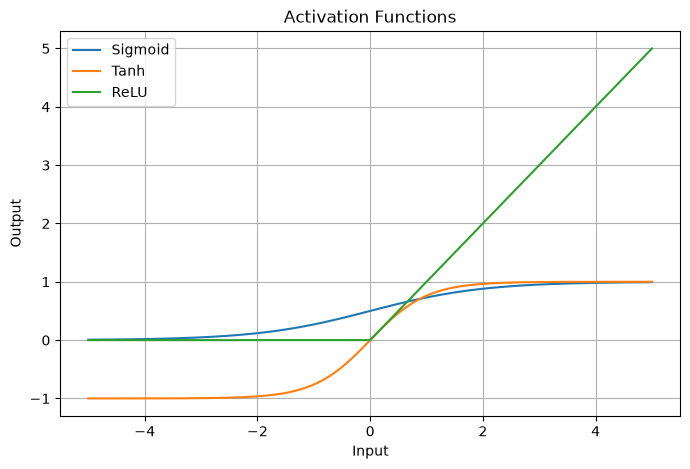

In [11]:
plt.figure(figsize=(8,5))

plt.plot(x, sigmoid(x), label="Sigmoid")
plt.plot(x, tanh(x), label="Tanh")
plt.plot(x, relu(x), label="ReLU")

plt.xlabel("Input")
plt.ylabel("Output")
plt.title("Activation Functions")
plt.legend()
plt.grid(True)
plt.show()

In [12]:
# Extra check: what each function gives for a few inputs
for v in [-5, -1, 0, 1, 5]:
    print(f"x = {v:3d}   sigmoid = {sigmoid(v):.3f}   tanh = {tanh(v):6.3f}   relu = {relu(v)}")

x =  -5   sigmoid = 0.007   tanh = -1.000   relu = 0
x =  -1   sigmoid = 0.269   tanh = -0.762   relu = 0
x =   0   sigmoid = 0.500   tanh =  0.000   relu = 0
x =   1   sigmoid = 0.731   tanh =  0.762   relu = 1
x =   5   sigmoid = 0.993   tanh =  1.000   relu = 5


# Task 3.1 – Interpretation

**1. What is the output range of the sigmoid function?**
**Answer:** Between 0 and 1 (it gets very close but never reaches them). At x = −5 it gives 0.007, at x = 0 it gives 0.5, at x = 5 it gives 0.993. It is an S-shaped curve.

**2. What is the output range of the tanh function?**
**Answer:** Between −1 and 1. Same S-shape as sigmoid, but centred on 0: tanh(0) = 0, tanh(−5) ≈ −1, tanh(5) ≈ 1.

**3. What happens to ReLU for negative inputs?**
**Answer:** The output is always 0. ReLU means “if the number is negative, make it 0; if it is positive, keep it”. So the line is flat at 0 on the left and goes straight up on the right.

**4. Why is a non-linear activation function important?**
**Answer:** Without it, stacking many layers is the same as having just one layer. Example: multiply by 2, then by 3 = just multiply by 6. Linear layers can only draw straight lines, but real data (images, prices) has curved, complicated patterns. The non-linear “bend” in each neuron is what lets the network learn those curved patterns.

**5. Why is ReLU commonly used in hidden layers?**
**Answer:** (1) It is very simple and fast: just max(0, x). (2) For positive inputs it never flattens out. Sigmoid and tanh go flat at both ends, so the learning signal becomes tiny there and deep networks learn very slowly (this is called the *vanishing gradient* problem). ReLU avoids this for positive values, so training is faster and works well in practice.

# Part IV – Image Classification with Keras

In [13]:
fashion_mnist = keras.datasets.fashion_mnist

(X_train_full, y_train_full), (X_test, y_test) = \
    fashion_mnist.load_data()

print("Training data:", X_train_full.shape)
print("Test data:", X_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training data: (60000, 28, 28)
Test data: (10000, 28, 28)


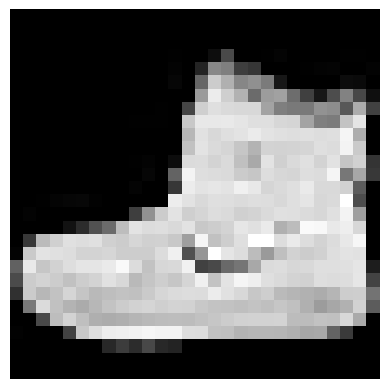

Class: 9


In [14]:
plt.imshow(X_train_full[0], cmap="gray")
plt.axis("off")
plt.show()

print("Class:", y_train_full[0])

In [15]:
# Extra: the class numbers 0-9 mean these clothing items (from the Fashion MNIST docs)
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("Class", y_train_full[0], "=", class_names[y_train_full[0]])
print("Pixel data type:", X_train_full.dtype)
print("Smallest pixel value:", X_train_full.min(), "  Largest pixel value:", X_train_full.max())

Class 9 = Ankle boot
Pixel data type: uint8
Smallest pixel value: 0   Largest pixel value: 255


In [16]:
X_valid = X_train_full[:5000]
y_valid = y_train_full[:5000]

X_train = X_train_full[5000:]
y_train = y_train_full[5000:]

In [17]:
X_train = X_train / 255.0
X_valid = X_valid / 255.0
X_test = X_test / 255.0

In [18]:
# Extra check: sizes after the split, and pixel range after scaling
print("Train:", X_train.shape, "  Valid:", X_valid.shape, "  Test:", X_test.shape)
print("Pixel range now:", X_train.min(), "to", X_train.max())

Train: (55000, 28, 28)   Valid: (5000, 28, 28)   Test: (10000, 28, 28)
Pixel range now: 0.0 to 1.0


# Task 4.1 – Interpretation

**1. What is the size of each image?**
**Answer:** 28 × 28 pixels = 784 pixels per image. There are 60,000 training images and 10,000 test images.

**2. What does a pixel value represent?**
**Answer:** How bright that tiny square is. 0 = black, 255 = white, and the numbers in between are shades of grey. The first image is class 9 = Ankle boot.

**3. Why is the image represented as a two-dimensional array?**
**Answer:** Because a picture is a grid: 28 rows and 28 columns. A 2D array keeps every pixel in its correct position (row, column), so we know which pixels are next to each other. That position information is what makes the shape of a boot or a shirt.

**4. Why are the pixel values divided by 255?**
**Answer:** To squeeze the values from 0–255 down to 0–1 (we checked: the range is now 0.0 to 1.0). Neural networks train faster and more stably with small inputs in a similar range. Big numbers make the weight updates too large and training can jump around.

**5. Why should the validation data be processed in the same way as the training data?**
**Answer:** The model only learns from 0–1 values. If we gave it validation (or test) images still in 0–255, it would see numbers it never saw in training and make bad predictions, so the score would mean nothing. The same rule must be applied to every set of data the model sees.

In [19]:
model = keras.models.Sequential([
    keras.layers.Flatten(input_shape=[28, 28]),
    keras.layers.Dense(300, activation="relu"),
    keras.layers.Dense(100, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])

c:\Users\lawre\Desktop\MSc AI and AUTOMATION\Intro To Artificial Intelligence and ML\AI_ML\iai600-intro-to-ai-ml\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [20]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# Extra check: where the parameter counts come from (weights + one bias per neuron)
print("Dense 1:", 784, "x", 300, "+", 300, "=", 784 * 300 + 300)
print("Dense 2:", 300, "x", 100, "+", 100, "=", 300 * 100 + 100)
print("Dense 3:", 100, "x", 10, "+", 10, "=", 100 * 10 + 10)
print("Total:  ", (784 * 300 + 300) + (300 * 100 + 100) + (100 * 10 + 10))

Dense 1: 784 x 300 + 300 = 235500
Dense 2: 300 x 100 + 100 = 30100
Dense 3: 100 x 10 + 10 = 1010
Total:   266610


# Task 4.2 – Interpretation

**1. What does the Flatten layer do?**
**Answer:** It unrolls the 28 × 28 grid into one long row of 784 numbers, so the Dense layers can use it. It learns nothing: it has 0 parameters.

**2. Why are there 784 input values?**
**Answer:** 28 × 28 = 784. One input value for every pixel in the image.

**3. What is the purpose of the hidden layers?**
**Answer:** They learn useful patterns step by step. The first hidden layer (300 neurons) combines raw pixels into simple patterns. The second (100 neurons) combines those into bigger, more useful patterns that help tell the clothing items apart. We call them “hidden” because we never see their values directly; only the input and output are visible.

**4. Why does the output layer contain 10 neurons?**
**Answer:** There are 10 clothing classes (T-shirt, trouser, pullover, dress, coat, sandal, shirt, sneaker, bag, ankle boot). Each output neuron gives the score for one class.

**5. Why is softmax used in the output layer?**
**Answer:** Softmax turns the 10 scores into probabilities: each one is between 0 and 1 and all 10 add up to 1. For example, “85% ankle boot, 10% sneaker, …”. The class with the highest probability is the prediction.

**6. What does the number of trainable parameters represent?**
**Answer:** The total number of weights and biases that the model adjusts during training: 266,610. Each Dense layer has (inputs × neurons) weights plus one bias per neuron: 784×300 + 300 = 235,500, then 300×100 + 100 = 30,100, then 100×10 + 10 = 1,010.

In [22]:
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="sgd",
    metrics=["accuracy"]
)

In [23]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    validation_data=(X_valid, y_valid)
)

Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7622 - loss: 0.7270 - val_accuracy: 0.8262 - val_loss: 0.5120
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8295 - loss: 0.4894 - val_accuracy: 0.8492 - val_loss: 0.4483
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8445 - loss: 0.4426 - val_accuracy: 0.8578 - val_loss: 0.4161
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8540 - loss: 0.4142 - val_accuracy: 0.8628 - val_loss: 0.3949
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8606 - loss: 0.3937 - val_accuracy: 0.8668 - val_loss: 0.3798
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8658 - loss: 0.3777 - val_accuracy: 0.8698 - val_loss: 0.3685
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8707 - loss: 0.3645 - val_accuracy: 0.8720 - val_loss: 0.3590
Epoch 8/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8742 - loss: 0.3530 - 

# Task 4.3 – Interpretation

**1. What is the purpose of the loss function?**
**Answer:** It gives one number that says how wrong the model's predictions are. Training tries to make this number smaller. `sparse_categorical_crossentropy` gives a big penalty when the model gives a low probability to the correct class. (“Sparse” just means the labels are plain numbers 0–9.) Our training loss went down from 0.7270 in epoch 1 to 0.2673 in epoch 20.

**2. What is the optimizer responsible for?**
**Answer:** Changing the weights to make the loss smaller. `sgd` (Stochastic Gradient Descent) takes a small batch of images (32 by default), works out which direction to move each weight to lower the loss, and takes a small step that way. This happens 1,719 times per epoch (55,000 ÷ 32, rounded up).

**3. What is an epoch?**
**Answer:** One full pass through all 55,000 training images. With `epochs=20`, the model sees every training image 20 times.

**4. What is the difference between training accuracy and validation accuracy?**
**Answer:** Training accuracy is measured on the images the model learns from. Validation accuracy is measured on 5,000 images it never learns from. At the end: training 0.9037 (90.4%) and validation 0.8860 (88.6%). Validation accuracy is the more honest one, because it shows how well the model works on new images.

**5. What would indicate that the model is overfitting?**
**Answer:** Training accuracy keeps going up, but validation accuracy stops improving or starts going down. In the same way, training loss keeps falling while validation loss starts rising. A big, growing gap between the two means the model is memorising the training images instead of learning general patterns.

In [24]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8725 - loss: 0.3516
Test loss: 0.3515811860561371
Test accuracy: 0.8725000023841858


In [25]:
# Extra check: train vs validation vs test, side by side (last epoch)
print(f"Training accuracy:   {history.history['accuracy'][-1]:.4f}")
print(f"Validation accuracy: {history.history['val_accuracy'][-1]:.4f}")
print(f"Test accuracy:       {test_accuracy:.4f}")

Training accuracy:   0.9033
Validation accuracy: 0.8860
Test accuracy:       0.8725


# Task 4.4 – Interpretation

**1. Training performance**
**Answer:** How well the model does on the data it learned from (accuracy 0.9037). This is like practising with the answer sheet next to you, so the score is too optimistic.

**2. Validation performance**
**Answer:** How well it does on 5,000 held-back images during development (accuracy 0.8860). We use it to check progress and make choices such as how many epochs or which model size to use. It is like a mock exam.

**3. Test performance**
**Answer:** How well it does on 10,000 images we never touched until the very end (accuracy 0.8727, loss 0.3503). It is like the final exam.

**4. Why should the test set be treated as an independent final evaluation?**
**Answer:** Because we make decisions based on the validation score, the model slowly becomes tuned to the validation set, so that score becomes a little too optimistic. The test set has had no influence on any decision, so it gives a fair, honest estimate of how the model will do on brand-new data. If we look at the test score and then change the model, it stops being a fair final exam. (Here the test accuracy, 87.3%, is a bit lower than validation, 88.6%, which is normal.)

# Part V – Understanding the Training Process

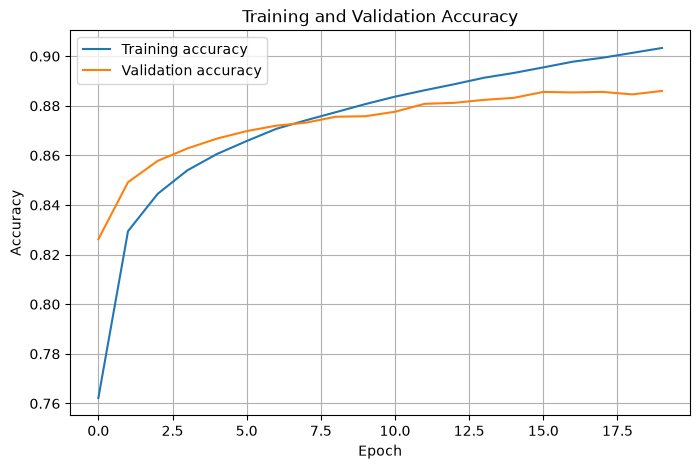

In [26]:
plt.figure(figsize=(8,5))

plt.plot(
    history.history["accuracy"],
    label="Training accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

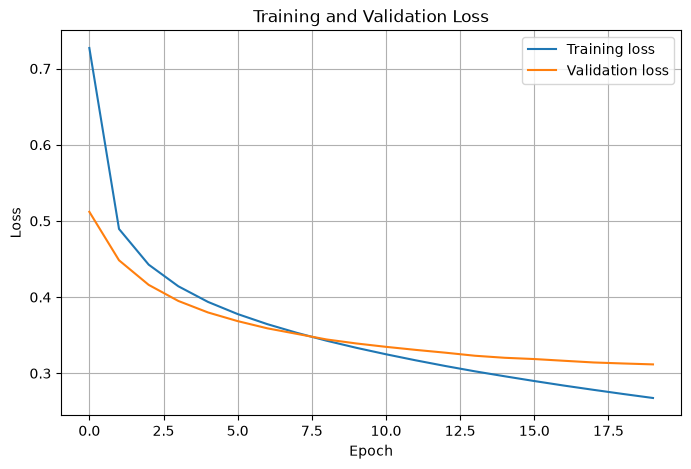

In [27]:
plt.figure(figsize=(8,5))

plt.plot(
    history.history["loss"],
    label="Training loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [28]:
# Extra check: the numbers behind the plots (epochs are counted from 1 here)
h = history.history
for e in [0, 4, 9, 14, 19]:
    print(f"Epoch {e+1:2d}:  train acc {h['accuracy'][e]:.4f}   val acc {h['val_accuracy'][e]:.4f}"
          f"   train loss {h['loss'][e]:.4f}   val loss {h['val_loss'][e]:.4f}")

best = int(np.argmin(h["val_loss"]))
print("\nLowest validation loss at epoch", best + 1, "->", round(h["val_loss"][best], 4))

Epoch  1:  train acc 0.7622   val acc 0.8262   train loss 0.7270   val loss 0.5120
Epoch  5:  train acc 0.8606   val acc 0.8668   train loss 0.3937   val loss 0.3798
Epoch 10:  train acc 0.8807   val acc 0.8758   train loss 0.3334   val loss 0.3391
Epoch 15:  train acc 0.8932   val acc 0.8832   train loss 0.2961   val loss 0.3203
Epoch 20:  train acc 0.9033   val acc 0.8860   train loss 0.2675   val loss 0.3117

Lowest validation loss at epoch 20 -> 0.3117


# Task 5.1 – Interpretation

**1. Does training accuracy improve with additional epochs?**
**Answer:** Yes, every time: 0.7622 (epoch 1) → 0.8605 (epoch 5) → 0.8809 (epoch 10) → 0.9037 (epoch 20). The biggest jumps are in the first few epochs, then it keeps rising more slowly.

**2. Does validation accuracy continue improving at the same rate?**
**Answer:** No. It improves fast at first (0.8262 → 0.8666 by epoch 5), then slows down: only 0.8750 → 0.8860 between epochs 10 and 20. It also wobbles a little (epoch 19 was 0.8874, epoch 20 was 0.8860). Training accuracy rose about 2.3 points in the second half, validation only about 1.1.

**3. Is there evidence of overfitting?**
**Answer:** Only a small early sign. The gap between training and validation accuracy grows (by epoch 20: 90.4% vs 88.6%). But validation loss was still going down and was lowest at the last epoch (0.3108), so the model is not really overfitting yet. (In the first epochs validation is even a bit higher than training. That is because Keras averages the training accuracy over the whole epoch while the model was still improving, but measures validation at the end of the epoch.)

**4. How could you modify the training process if overfitting occurs?**
**Answer:** Stop training earlier, at the epoch where validation loss is lowest. Keras can do this automatically with *early stopping* (Part XI). Other options: use a smaller model (fewer neurons or layers), get more training data, or add *regularisation* (extra rules that stop the model memorising, such as dropout).

# Part VI – Neural Network Regression

In [29]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing()

X = housing.data
y = housing.target

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (20640, 8)
y shape: (20640,)


In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

In [31]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)
X_test = scaler.transform(X_test)

In [32]:
regression_model = keras.models.Sequential([
    keras.layers.Dense(30, activation="relu",
                       input_shape=X_train.shape[1:]),
    keras.layers.Dense(30, activation="relu"),
    keras.layers.Dense(1)
])

c:\Users\lawre\Desktop\MSc AI and AUTOMATION\Intro To Artificial Intelligence and ML\AI_ML\iai600-intro-to-ai-ml\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [33]:
regression_model.compile(
    loss="mean_squared_error",
    optimizer="sgd"
)

In [34]:
regression_history = regression_model.fit(
    X_train,
    y_train,
    epochs=20,
    validation_data=(X_valid, y_valid)
)

Epoch 1/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6902 - val_loss: 0.7206
Epoch 2/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4475 - val_loss: 0.4375
Epoch 3/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4046 - val_loss: 0.4163
Epoch 4/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3873 - val_loss: 0.4037
Epoch 5/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3753 - val_loss: 0.3947
Epoch 6/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3663 - val_loss: 0.3878
Epoch 7/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3592 - val_loss: 0.3821
Epoch 8/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3531 - val_loss: 0.3788
Epoch 9/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3482 - val_loss: 0.3751
Epoch 10/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3439 - val_loss: 0.3727
Epoch 11/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3403 - val_loss: 0.3703
Epoch 12/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

In [35]:
test_mse = regression_model.evaluate(
    X_test,
    y_test
)

print("Test MSE:", test_mse)

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3270
Test MSE: 0.32699576020240784


In [36]:
# Extra check: what the MSE means in real money, and a "dumb" baseline to compare with
# (the target is the median house value in units of $100,000)
rmse = np.sqrt(test_mse)
print(f"Test RMSE: {rmse:.3f}  ->  typical error of about ${rmse * 100_000:,.0f}")

baseline_mse = np.mean((y_test - y_train.mean()) ** 2)
print(f"Baseline MSE (always guess the average price): {baseline_mse:.3f}")

print("\nFirst 5 predictions vs real values:")
preds = regression_model.predict(X_test[:5], verbose=0).ravel()
for p, t in zip(preds, y_test[:5]):
    print(f"  predicted {p:.2f}   actual {t:.2f}")

Test RMSE: 0.572  ->  typical error of about $57,184
Baseline MSE (always guess the average price): 1.311

First 5 predictions vs real values:
  predicted 0.66   actual 0.48
  predicted 1.46   actual 0.46
  predicted 4.13   actual 5.00
  predicted 2.65   actual 2.19
  predicted 2.99   actual 2.78


# Task 6.1 – Interpretation

**1. Why is feature scaling particularly important when training neural networks?**
**Answer:** The features are on very different scales. For example, Population is in the hundreds or thousands while AveBedrms is around 1. Gradient descent uses one learning rate for all weights, so big-valued features cause big jumps and small ones barely move, and training becomes slow or unstable. `StandardScaler` puts every feature on the same scale (average 0, spread 1). It is fitted on the training data only, then the same rule is applied to validation and test.

**2. Why does the output layer contain only one neuron?**
**Answer:** We predict one number: the median house value of a district (in units of $100,000). One number to predict = one output neuron.

**3. Why is a linear output used rather than softmax?**
**Answer:** A house price can be any number, so the output must not be squeezed. `Dense(1)` with no activation just outputs the raw number. Softmax is for picking between classes: it forces the outputs to add up to 1. With only one neuron, softmax would always output exactly 1.0, which is useless for prices.

**4. Why is mean squared error appropriate for this regression problem?**
**Answer:** MSE takes the difference between each predicted and real price, squares it, and averages them. This works well for continuous numbers, and squaring punishes big mistakes more than small ones. Our test MSE is 0.327. Its square root (RMSE) is 0.572, so the typical error is about $57,000. Always guessing the average price gives MSE 1.311, so our model is about 4 times better than that.

**5. How is this neural-network regression problem different from the classification problem in Fashion MNIST?**
**Answer:**
- **Goal:** Fashion MNIST picks one of 10 categories; here we predict a number (a price).
- **Output layer:** 10 neurons + softmax there; 1 neuron with no activation here.
- **Loss:** crossentropy there; mean squared error here.
- **Metric:** accuracy there; here there is no accuracy, because a price prediction is never exactly right, so we measure how far off it is (MSE).
- **Input:** 784 pixel values there; 8 columns of house data here.

# Part VII – Wide & Deep Neural Networks (optional)

In [37]:
X_train_A = X_train[:, :5]
X_train_B = X_train[:, 5:]

X_valid_A = X_valid[:, :5]
X_valid_B = X_valid[:, 5:]

X_test_A = X_test[:, :5]
X_test_B = X_test[:, 5:]

In [38]:
# Extra check: which features went into each group
print("Group A (wide path): ", housing.feature_names[:5])
print("Group B (deep path): ", housing.feature_names[5:])

Group A (wide path):  ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population']
Group B (deep path):  ['AveOccup', 'Latitude', 'Longitude']


In [39]:
input_A = keras.layers.Input(shape=X_train_A.shape[1:])
input_B = keras.layers.Input(shape=X_train_B.shape[1:])

hidden_1 = keras.layers.Dense(
    30,
    activation="relu"
)(input_B)

hidden_2 = keras.layers.Dense(
    30,
    activation="relu"
)(hidden_1)

concat = keras.layers.concatenate([
    input_A,
    hidden_2
])

output = keras.layers.Dense(1)(concat)

wide_deep_model = keras.Model(
    inputs=[input_A, input_B],
    outputs=[output]
)

In [40]:
wide_deep_model.compile(
    loss="mse",
    optimizer="sgd"
)

In [41]:
wide_deep_history = wide_deep_model.fit(
    [X_train_A, X_train_B],
    y_train,
    epochs=20,
    validation_data=(
        [X_valid_A, X_valid_B],
        y_valid
    )
)

Epoch 1/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.8399 - val_loss: 70.1543
Epoch 2/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 1.5698 - val_loss: 0.4794
Epoch 3/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4165 - val_loss: 0.4476
Epoch 4/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4039 - val_loss: 0.4355
Epoch 5/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3968 - val_loss: 0.4284
Epoch 6/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3923 - val_loss: 0.4240
Epoch 7/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3889 - val_loss: 0.4199
Epoch 8/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3861 - val_loss: 0.4168
Epoch 9/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3836 - val_loss: 0.4140
Epoch 10/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3812 - val_loss: 0.4112
Epoch 11/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3790 - val_loss: 0.4084
Epoch 12/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/ste

In [42]:
# Extra check: the layer layout, and test MSE compared with the Part VI model
wide_deep_model.summary()

wide_deep_mse = wide_deep_model.evaluate([X_test_A, X_test_B], y_test, verbose=0)
print("Sequential model (Part VI) test MSE:", round(test_mse, 4))
print("Wide & Deep model          test MSE:", round(wide_deep_mse, 4))

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 30)        │        120 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 30)        │        930 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 35)        │          0 │ input_layer_2[0]… │
│ (Concatenate)       │                   │            │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 1)         │         36 │ concatenate[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,088 (4.25 KB)

 Trainable params: 1,086 (4.24 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

Sequential model (Part VI) test MSE: 0.327
Wide & Deep model          test MSE: 0.3775


# Task 7.1 – Interpretation

**1. What is the “wide” part of this architecture?**
**Answer:** Input A (MedInc, HouseAge, AveRooms, AveBedrms, Population) goes straight to the output layer and skips the hidden layers. It is a shortcut: these features are only combined in a simple, straight-line way.

**2. What is the “deep” part?**
**Answer:** Input B (AveOccup, Latitude, Longitude) goes through two hidden layers of 30 ReLU neurons each. That path can learn complicated, curved patterns. Then it joins the wide path (`concatenate`) before the final output neuron.

**3. Why might different groups of features be processed differently?**
**Answer:** Some features have a simple link to the target. For example, higher income generally means more expensive houses, so a straight shortcut is enough. Others have complicated effects that need deep processing. For example, Latitude and Longitude together say *where* a house is (coast or inland, city or countryside). Wide & Deep lets the model remember simple rules and learn complex patterns at the same time. Note: in our run Wide & Deep did slightly worse (test MSE 0.377 vs 0.327 for the Part VI model). Our split of the features is just an example, and income, the strongest feature, only got the simple path.

**4. How is this model different from the Sequential models used earlier?**
**Answer:** A Sequential model is one straight chain: one input goes through each layer in order. This model has two inputs, a branch, and a merge (`concatenate`), so it cannot be a straight chain. It is built with the **Functional API**: we connect layers by hand (`layer(...)(previous_layer)`), then create it with `keras.Model(inputs=[...], outputs=[...])`. When training, we give it a list of two inputs: `[X_train_A, X_train_B]`.

# Part VIII – Auxiliary Output

In [43]:
input_layer = keras.layers.Input(
    shape=X_train.shape[1:]
)

hidden_1 = keras.layers.Dense(
    30,
    activation="relu"
)(input_layer)

hidden_2 = keras.layers.Dense(
    30,
    activation="relu"
)(hidden_1)

aux_output = keras.layers.Dense(
    1,
    name="aux_output"
)(hidden_2)

hidden_3 = keras.layers.Dense(
    30,
    activation="relu"
)(hidden_2)

main_output = keras.layers.Dense(
    1,
    name="main_output"
)(hidden_3)

aux_model = keras.Model(
    inputs=input_layer,
    outputs=[main_output, aux_output]
)

In [44]:
aux_model.compile(
    loss=["mse", "mse"],
    loss_weights=[0.9, 0.1],
    optimizer="sgd"
)

In [45]:
aux_history = aux_model.fit(
    X_train,
    [y_train, y_train],
    epochs=20,
    validation_data=(
        X_valid,
        [y_valid, y_valid]
    )
)

Epoch 1/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - aux_output_loss: 1.3495 - loss: 0.7987 - main_output_loss: 0.7373 - val_aux_output_loss: 0.7351 - val_loss: 0.7370 - val_main_output_loss: 0.7368
Epoch 2/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - aux_output_loss: 0.5450 - loss: 0.4660 - main_output_loss: 0.4571 - val_aux_output_loss: 0.5373 - val_loss: 0.5533 - val_main_output_loss: 0.5546
Epoch 3/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - aux_output_loss: 0.4752 - loss: 0.4129 - main_output_loss: 0.4059 - val_aux_output_loss: 0.4780 - val_loss: 0.4576 - val_main_output_loss: 0.4556
Epoch 4/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - aux_output_loss: 0.4434 - loss: 0.3880 - main_output_loss: 0.3818 - val_aux_output_loss: 0.4501 - val_loss: 0.4342 - val_main_output_loss: 0.4328
Epoch 5/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - aux_output_loss: 0.4256 - loss: 0.3755 - main_output_loss: 0.3699 - val_aux_output_loss: 0.4392 - val_loss: 0.4300 - val_main_output_loss: 0.4292


In [46]:
# Extra check: the model now returns TWO predictions per house
main_pred, aux_pred = aux_model.predict(X_test[:3], verbose=0)
for m, a, t in zip(main_pred.ravel(), aux_pred.ravel(), y_test[:3]):
    print(f"main output {m:.2f}   aux output {a:.2f}   actual {t:.2f}")

results = aux_model.evaluate(X_test, [y_test, y_test], verbose=0, return_dict=True)
for k, v in results.items():
    print(f"{k:20s} {v:.4f}")

main output 0.81   aux output 0.67   actual 0.48
main output 1.84   aux output 1.79   actual 0.46
main output 4.53   aux output 3.66   actual 5.00
aux_output_loss      0.3633
loss                 0.3277
main_output_loss     0.3237


## Notes – What Part VIII shows

- **Two outputs:** the model gives two predictions per house. `aux_output` comes from the middle of the network (after `hidden_2`), and `main_output` comes from the end (after `hidden_3`).
- **Weighted loss:** total loss = 0.9 × main loss + 0.1 × aux loss. Check: 0.9 × 0.3229 + 0.1 × 0.3624 ≈ 0.3269 (the `loss` printed above). The main output matters most.
- **Why bother:** the auxiliary output forces the middle layers to be useful on their own. This gives the network an extra learning signal and can reduce overfitting (it acts as a kind of *regularisation*).
- **Result:** main output test MSE 0.3229, which is better than the aux output's 0.3624 because it has one more layer. It is about the same as the Part VI model (0.327).
- We give the target twice, `[y_train, y_train]`, because both outputs predict the same house price.
- For real predictions you use only the main output. The aux output is a training helper.

# Part IX – Dynamic Models with the Subclassing API

In [47]:
class CustomModel(keras.Model):

    def __init__(self):
        super().__init__()

        self.hidden1 = keras.layers.Dense(
            30,
            activation="relu"
        )

        self.hidden2 = keras.layers.Dense(
            30,
            activation="relu"
        )

        self.output_layer = keras.layers.Dense(1)

    def call(self, inputs):

        x = self.hidden1(inputs)
        x = self.hidden2(x)

        return self.output_layer(x)

In [48]:
custom_model = CustomModel()

In [49]:
custom_model.compile(
    loss="mse",
    optimizer="sgd"
)

In [50]:
custom_model.fit(
    X_train,
    y_train,
    epochs=10,
    validation_data=(X_valid, y_valid)
)

Epoch 1/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6876 - val_loss: 0.8856
Epoch 2/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4915 - val_loss: 0.5386
Epoch 3/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4262 - val_loss: 0.4338
Epoch 4/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4026 - val_loss: 0.4203
Epoch 5/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3892 - val_loss: 0.4122
Epoch 6/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3793 - val_loss: 0.4040
Epoch 7/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3708 - val_loss: 0.3987
Epoch 8/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3635 - val_loss: 0.3941
Epoch 9/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3567 - val_loss: 0.3907
Epoch 10/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3511 - val_loss: 0.3885


In [51]:
# Extra check: test MSE of the subclassed model (only 10 epochs, vs 20 for Part VI)
custom_mse = custom_model.evaluate(X_test, y_test, verbose=0)
print("Custom (subclassed) model test MSE:", round(custom_mse, 4))

Custom (subclassed) model test MSE: 0.3723


## Notes – What Part IX shows

- **Subclassing API:** instead of listing layers, we write our own Python class. The layers are created in `__init__`, and `call()` says how data flows through them (the *forward pass*).
- **Why it is useful:** inside `call()` you can use normal Python, such as `if` statements and loops, so the model can behave differently for different inputs. That is why it is called “dynamic”.
- **Downside:** Keras cannot see the model's structure until it has been run on data, so it is harder to inspect (for example `summary()`) and to save and reload.
- **Result:** test MSE 0.3723. It has the same layers as the Part VI model (30-30-1), but was trained for only 10 epochs instead of 20, which mainly explains why it is a little worse than 0.327.

# Part X – Saving and Restoring a Neural Network

In [52]:
# Save the California Housing regression model
regression_model.save("california_housing_model.keras")
print("Model saved successfully!")

Model saved successfully!


In [53]:
loaded_regression_model = keras.models.load_model("california_housing_model.keras")

In [54]:
reg_test_loss = loaded_regression_model.evaluate(X_test, y_test)
print("Loaded Regression Model Test MSE:", reg_test_loss)

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3270  
Loaded Regression Model Test MSE: 0.32699576020240784


In [55]:
# Extra check: the loaded model should give exactly the same result as the original
import os
print("File size:", round(os.path.getsize("california_housing_model.keras") / 1024, 1), "KB")
print("Original model test MSE:", test_mse)
print("Loaded model test MSE:  ", reg_test_loss)
print("Identical predictions:  ",
      np.allclose(regression_model.predict(X_test, verbose=0),
                  loaded_regression_model.predict(X_test, verbose=0)))

File size: 26.1 KB
Original model test MSE: 0.32699576020240784
Loaded model test MSE:   0.32699576020240784
Identical predictions:   True


## Notes – What Part X shows

- `.save("california_housing_model.keras")` stores everything in one file (26.1 KB): the layer structure, all learned weights, and the training settings.
- `load_model(...)` brings it back. The loaded model gives exactly the same test MSE (0.32699576…) and identical predictions, so nothing was lost.
- **Why it matters:** you train once and reuse the model later (for example in an app) without training again.

# Part XI – Callbacks

In [56]:
early_stopping = keras.callbacks.EarlyStopping(
    patience=5,
    restore_best_weights=True
)

In [57]:
history_callback = regression_model.fit(
    X_train,
    y_train,
    epochs=20,
    validation_data=(X_valid, y_valid),
    callbacks=[early_stopping]
)

Epoch 1/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3150 - val_loss: 0.3439
Epoch 2/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3135 - val_loss: 0.3428
Epoch 3/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3118 - val_loss: 0.3417
Epoch 4/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3103 - val_loss: 0.3407
Epoch 5/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3090 - val_loss: 0.3398
Epoch 6/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3078 - val_loss: 0.3380
Epoch 7/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3066 - val_loss: 0.3364
Epoch 8/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3056 - val_loss: 0.3355
Epoch 9/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3046 - val_loss: 0.3345
Epoch 10/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3035 - val_loss: 0.3335
Epoch 11/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3025 - val_loss: 0.3327
Epoch 12/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step

In [58]:
# Extra check: did early stopping actually stop training?
epochs_run = len(history_callback.history["val_loss"])
best_epoch = int(np.argmin(history_callback.history["val_loss"])) + 1
print("Epochs actually run:", epochs_run, "of 20")
print("Best epoch (lowest val loss):", best_epoch,
      "->", round(min(history_callback.history["val_loss"]), 4))
print("Stopped early:", early_stopping.stopped_epoch > 0)

Epochs actually run: 20 of 20
Best epoch (lowest val loss): 18 -> 0.3234
Stopped early: False


## Notes – What Part XI shows

- **Callback:** a helper that Keras runs automatically during training (for example at the end of each epoch).
- **EarlyStopping(patience=5, restore_best_weights=True):** it watches the validation loss. If the loss has not improved for 5 epochs in a row, it stops training and goes back to the weights from the best epoch.
- **What happened here:** it never stopped. All 20 of 20 epochs ran, and the best epoch was the last one (validation loss 0.3233). The validation loss was still improving, so there was no reason to stop. With a much higher `epochs` (for example 200), it would stop by itself at the right time.
- **Note:** `fit()` on `regression_model` again continues from its Part VI weights; it does not start from zero. That is why the loss is already low (0.3150) in epoch 1.

# Part XII – TensorBoard

In [59]:
import os

root_logdir = os.path.join(
    os.curdir,
    "my_logs"
)

In [60]:
import time

def get_run_logdir():
    run_id = time.strftime(
        "run_%Y_%m_%d-%H_%M_%S"
    )

    return os.path.join(
        root_logdir,
        run_id
    )

run_logdir = get_run_logdir()

print(run_logdir)

.\my_logs\run_2026_10_13-14_46_11


In [61]:
tensorboard_cb = keras.callbacks.TensorBoard(
    run_logdir
)

In [62]:
regression_model.fit(
    X_train,
    y_train,
    epochs=20,
    validation_data=(X_valid, y_valid),
    callbacks=[tensorboard_cb]
)

Epoch 1/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2963 - val_loss: 0.3235
Epoch 2/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2957 - val_loss: 0.3288
Epoch 3/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2959 - val_loss: 0.3326
Epoch 4/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2959 - val_loss: 0.3246
Epoch 5/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2941 - val_loss: 0.3234
Epoch 6/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2935 - val_loss: 0.3228
Epoch 7/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2930 - val_loss: 0.3228
Epoch 8/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2924 - val_loss: 0.3218
Epoch 9/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2918 - val_loss: 0.3218
Epoch 10/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2911 - val_loss: 0.3218
Epoch 11/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2907 - val_loss: 0.3210
Epoch 12/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

In [63]:
# Extra check: what TensorBoard wrote to disk
for folder, _, files in os.walk(run_logdir):
    for f in files:
        print(os.path.join(folder, f))

.\my_logs\run_2026_10_13-14_46_11\train\events.out.tfevents.1791895571.NIPPY.41864.0.v2
.\my_logs\run_2026_10_13-14_46_11\validation\events.out.tfevents.1791895573.NIPPY.41864.1.v2


**Viewing TensorBoard in VS Code (not Colab):** the two `%` lines below are the lab's Colab version.
If nothing shows up inside VS Code, open a PowerShell terminal in the `lab06` folder (with the venv active) and run:

    

then open http://localhost:6006 in your browser. Press `Ctrl + C` in the terminal to stop it.tensorboard --logdir my_logs

In [64]:
%load_ext tensorboard
%tensorboard --logdir=./my_logs

## Notes – What Part XII shows

- **TensorBoard** is a web dashboard for watching and comparing training runs (loss curves, and more).
- The `TensorBoard` callback writes log files during training: one folder for `train` and one for `validation` (see the file list above).
- Each run gets its own timestamped folder inside `my_logs`, so TensorBoard can show several runs on one chart to compare them.
- Training here again continues the same `regression_model`. It ended with validation loss 0.3144.

# Part XIII – Basic Hyperparameter Fine-Tuning

In [65]:
small_model = keras.models.Sequential([
    keras.layers.Input(shape=(8,)),
    keras.layers.Dense(50, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])

small_model.compile(loss="sparse_categorical_crossentropy", optimizer="sgd", metrics=["accuracy"])

In [66]:
small_history = small_model.fit(
    X_train,
    y_train,
    epochs=10,
    validation_data=(X_valid, y_valid)
)

Epoch 1/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0027 - loss: 1.8087 - val_accuracy: 0.0039 - val_loss: 1.4894
Epoch 2/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.0029 - loss: 1.3785 - val_accuracy: 0.0042 - val_loss: 1.3074
Epoch 3/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.0027 - loss: 1.2539 - val_accuracy: 0.0036 - val_loss: 1.2236
Epoch 4/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.0023 - loss: 1.1876 - val_accuracy: 0.0036 - val_loss: 1.1732
Epoch 5/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.0023 - loss: 1.1448 - val_accuracy: 0.0036 - val_loss: 1.1386
Epoch 6/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.0024 - loss: 1.1140 - val_accuracy: 0.0039 - val_loss: 1.1125
Epoch 7/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.0024 - loss: 1.0901 - val_accuracy: 0.0039 - val_loss: 1.0915
Epoch 8/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.0025 - loss: 1.0706 - val_accuracy: 0.

> **⚠️ Note on the code above (mistake in the lab sheet):** at this point `X_train`/`y_train` hold the **California Housing** data, because Part VI replaced them. So this code builds a *classifier* (10 softmax outputs) but feeds it house prices as if they were class labels. For the loss, Keras cuts off the decimals (2.53 → class 2). But the accuracy check compares the exact price (2.53) with the predicted class (2), so it almost never matches, and validation accuracy is only about 0.004 (0.4%). The code runs, but the result means nothing.
>
> The sheet says to compare with “the larger network”, which is the Fashion MNIST model from Part IV. So the next cell builds what was most likely intended: a **smaller Fashion MNIST model** (50 hidden neurons instead of 300 + 100).

In [67]:
# Corrected version: a smaller FASHION MNIST model, so we can compare it with the big one from Part IV.
# X_train etc. now hold housing data, so we reload Fashion MNIST under new names.
(X_fm_full, y_fm_full), (X_fm_test, y_fm_test) = keras.datasets.fashion_mnist.load_data()
X_fm_valid, y_fm_valid = X_fm_full[:5000] / 255.0, y_fm_full[:5000]
X_fm_train, y_fm_train = X_fm_full[5000:] / 255.0, y_fm_full[5000:]

small_fm_model = keras.models.Sequential([
    keras.layers.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(50, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])
small_fm_model.compile(loss="sparse_categorical_crossentropy", optimizer="sgd", metrics=["accuracy"])

small_fm_history = small_fm_model.fit(
    X_fm_train, y_fm_train,
    epochs=10,
    validation_data=(X_fm_valid, y_fm_valid),
    verbose=0
)

In [68]:
# Compare: small model (50 neurons) vs large model from Part IV (300 + 100 neurons), both after 10 epochs
print(f"Small model parameters: {small_fm_model.count_params():,}")
print(f"Large model parameters: {model.count_params():,}")
print()
print(f"Small model val accuracy after 10 epochs: {small_fm_history.history['val_accuracy'][-1]:.4f}")
print(f"Large model val accuracy after 10 epochs: {history.history['val_accuracy'][9]:.4f}")
print(f"Large model val accuracy after 20 epochs: {history.history['val_accuracy'][-1]:.4f}")

Small model parameters: 39,760
Large model parameters: 266,610

Small model val accuracy after 10 epochs: 0.8624
Large model val accuracy after 10 epochs: 0.8758
Large model val accuracy after 20 epochs: 0.8860


In [69]:
optimizer_fast = keras.optimizers.SGD(
    learning_rate=0.1
)

optimizer_slow = keras.optimizers.SGD(
    learning_rate=0.01
)

In [70]:
# Train two otherwise identical small Fashion MNIST models, one per learning rate
def make_small_model(optimizer):
    m = keras.models.Sequential([
        keras.layers.Input(shape=(28, 28)),
        keras.layers.Flatten(),
        keras.layers.Dense(50, activation="relu"),
        keras.layers.Dense(10, activation="softmax")
    ])
    m.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer, metrics=["accuracy"])
    return m

keras.utils.set_random_seed(42)
fast_model = make_small_model(optimizer_fast)
fast_history = fast_model.fit(X_fm_train, y_fm_train, epochs=10,
                              validation_data=(X_fm_valid, y_fm_valid), verbose=0)

keras.utils.set_random_seed(42)
slow_model = make_small_model(optimizer_slow)
slow_history = slow_model.fit(X_fm_train, y_fm_train, epochs=10,
                              validation_data=(X_fm_valid, y_fm_valid), verbose=0)

for e in range(10):
    print(f"Epoch {e+1:2d}:  lr=0.1 val acc {fast_history.history['val_accuracy'][e]:.4f}"
          f"   |   lr=0.01 val acc {slow_history.history['val_accuracy'][e]:.4f}")

Epoch  1:  lr=0.1 val acc 0.8214   |   lr=0.01 val acc 0.8146
Epoch  2:  lr=0.1 val acc 0.8520   |   lr=0.01 val acc 0.8354
Epoch  3:  lr=0.1 val acc 0.8600   |   lr=0.01 val acc 0.8458
Epoch  4:  lr=0.1 val acc 0.8620   |   lr=0.01 val acc 0.8510
Epoch  5:  lr=0.1 val acc 0.8656   |   lr=0.01 val acc 0.8556
Epoch  6:  lr=0.1 val acc 0.8684   |   lr=0.01 val acc 0.8568
Epoch  7:  lr=0.1 val acc 0.8712   |   lr=0.01 val acc 0.8610
Epoch  8:  lr=0.1 val acc 0.8724   |   lr=0.01 val acc 0.8626
Epoch  9:  lr=0.1 val acc 0.8740   |   lr=0.01 val acc 0.8636
Epoch 10:  lr=0.1 val acc 0.8744   |   lr=0.01 val acc 0.8628


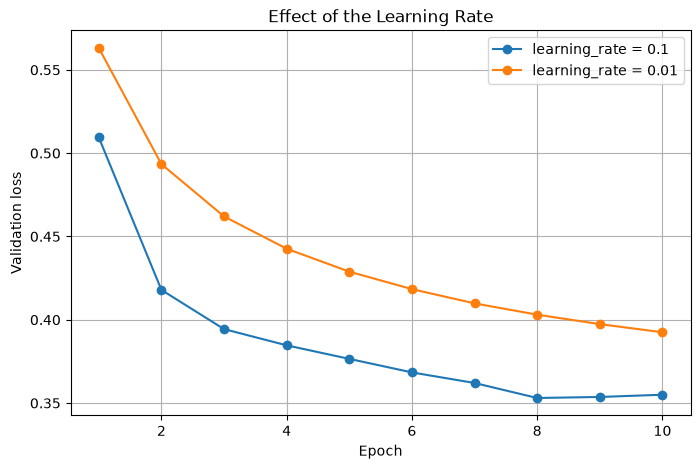

In [71]:
plt.figure(figsize=(8,5))
plt.plot(range(1, 11), fast_history.history["val_loss"], marker="o", label="learning_rate = 0.1")
plt.plot(range(1, 11), slow_history.history["val_loss"], marker="o", label="learning_rate = 0.01")
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Effect of the Learning Rate")
plt.legend()
plt.grid(True)
plt.show()

## Notes – What Part XIII shows

- **Hyperparameters** are settings **we** choose before training: number of layers, neurons per layer, learning rate, batch size, epochs, optimizer. The model does not learn them. **Parameters** (weights and biases) are what the model learns.
- **Fewer neurons:** the small model has 39,760 parameters, compared with 266,610 for the large one (about 6.7 times fewer). After 10 epochs its validation accuracy is 0.8630, compared with 0.8750 for the large model. That is only about 1.2 points worse, so the small model is good for its size, and the large one gains a little from its extra capacity.
- **Learning rate** is the size of each weight-update step. 0.01 is Keras's default for `sgd`, so all the earlier models used it.
  - With 0.1 (big steps), the model learned faster: validation accuracy 0.8754 after 10 epochs, compared with 0.8636 for 0.01.
  - Too big a learning rate can make training jump around or blow up (the loss goes to huge numbers or `nan`). Too small makes training very slow. A good value is usually found by trying a few, exactly like this.